<div style="background-color:white; display:block; text-align:center; padding:5px;">
    <img src="https://imgur.com/vCrtMAT.jpg" alt="Logo" width="2000">
</div>

# Table of Contents
1. [Previous settings](#1.-Previous-settings)
2. [Inputs](#2.-INPUTS)
3. [Compute turbine noise spectra](#3.-Compute-turbine-noise-spectra)
6. [Load Seabed geoacoustic properties](#4.-Load-seabed-geoacoustic-properties)
5. [Load EMODnet Bathymetry](#5.-Load-EMODnet-Bathymetry)
6. [Load temperature and salinity](#6.-Load-temperature-and-salinity)
7. [Run RAM/Bellhop propagation model](#7.-Run-RAM/Bellhop-propagation-model)
8. [Plot desired figures](#8.-Plot-desired-figures)

# User manual

The steps to run the PUREWIND tool are the following.

0. For the **first run, uncomment** al [**pip install**](#Installation-of-required-modules) lines (by removing initial **#**). 
1. Define the [**working directory**](#Define-working-directory). The VRE path is set by default, but if you want to run the code locally, you must specify the path where PUREWIND Tools are stored.
2. Specify the [**inputs**](#2.-INPUTS) for the prediction and propagation model.
3.	If required, add additional frequencies and corresponding source levels to the frequency and Source Level arrays([**f_ and SL_**](#3.-Compute-turbine-noise-spectra) ,respectively).
4. Click the ⏩ **Run All Cells** button in the toolbar.
5. Insert [**Copernicus Marine**](#6.-Load-temperature-and-salinity) credentials. If not done yet, create a user account in https://data.marine.copernicus.eu/register.
6. When the propagation model has been run, [**plot**](#8.-Plot-desired-figures) the desired figures. All generated files (.npz) and figures (.png) are stored in a folder with the defined [name](#2.-INPUTS) inside the PWT_outputs folder.

# 1. Previous settings

## Installation of required modules

For the **first run, uncomment** all pip install lines (by removing initial #), so necesary modules can be installed/updated.

In [79]:
#pip install mat4py

In [80]:
#pip install pyram

In [81]:
#pip install "numpy<2"

In [82]:
#pip install ipywidgets

In [83]:
#pip install erdappy

In [84]:
#pip install copernicusmarine

In [85]:
##pip install "xarray<2023.2"

In [86]:
#pip install "zarr<3"

## Define working directory
Specify the path containing the PUREWIND files (pyram.py, aux, Bellhop_linux.exe,...)

In [87]:
# PW path
import os
PW_path=r'/Users/ionurtiaga/Documents/PUREWIND/PureWindTool/'
PW_path = os.getcwd()


Specify the path where **OUTPUT** files will be stored (the script will create an output folder within this path)

In [88]:
Store_path=r'/Users/ionurtiaga/Documents/PUREWIND/PureWindTool/'
Store_path = os.getcwd()

## PUREWIND Modules and libraries import and definition

In [89]:
#Prelocated variables
_pca = None
_spettri_base = None
_mu = None
_gpr_models = None
_df = None
# Standard library imports
import math
import os
import sys
import shutil
import subprocess
import time as tm
from datetime import datetime
from io import StringIO
from random import randrange, shuffle
from struct import unpack
import warnings

# Suppress warnings
warnings.filterwarnings("ignore")

# Third-party imports
import numpy as np
from numpy import save, broadcast_to, log10
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from mpl_toolkits.axes_grid1 import make_axes_locatable
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import netCDF4 as nc
import xarray as xr
import pyproj
from PIL import Image
import requests
from sklearn.decomposition import PCA
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from mat4py import loadmat
from IPython.display import display
import ipywidgets as widgets
from ipywidgets import IntSlider, RadioButtons, Button, VBox, Output

import pyram as pyram
from pyram.PyRAM import PyRAM
# Local or modified module imports
#shutil.copyfile('PyRAM.py', '/opt/conda/lib/python3.11/site-packages/pyram/PyRAM.py')/Users/ionurtiaga/.pyenv/versions/3.11.9/lib/python3.11/site-packages/pyram
shutil.copyfile('PyRAM.py', pyram.__path__[0]+'/PyRAM.py')

from IPython.display import clear_output

import copernicusmarine

import platform

#Pure Wind build libraries
def closest(lst, K):
    """Find the closest value in a list to K."""
    lst1 = np.asarray(lst)
    idx = (np.abs(lst1 - K)).argmin()
    return lst1[idx]

def Get_Column(matrix, i):
    """Return the i-th column of a 2D list."""
    return [row[i] for row in matrix]

def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in meters."""
    R = 6371000
    phi1, phi2 = map(math.radians, [lat1, lat2])
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2)**2
    return R * 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

# %% NetCDF Introspection

def ncdump(nc_fid, verb=True):
    """Mimic NCAR's ncdump for NetCDF4 datasets."""
    def print_ncattr(key):
        try:
            print(f"\t\ttype: {repr(nc_fid.variables[key].dtype)}")
            for attr in nc_fid.variables[key].ncattrs():
                print(f'\t\t{attr}: {repr(nc_fid.variables[key].getncattr(attr))}')
        except KeyError:
            print(f"\t\tWARNING: {key} has no attributes")

    nc_attrs = nc_fid.ncattrs()
    nc_dims = list(nc_fid.dimensions)
    nc_vars = list(nc_fid.variables)

    if verb:
        print("NetCDF Global Attributes:")
        for attr in nc_attrs:
            print(f'\t{attr}: {repr(nc_fid.getncattr(attr))}')
        print("NetCDF dimension information:")
        for dim in nc_dims:
            print(f"\tName: {dim}\n\t\tsize: {len(nc_fid.dimensions[dim])}")
            print_ncattr(dim)
        print("NetCDF variable information:")
        for var in nc_vars:
            if var not in nc_dims:
                print(f'\tName: {var}\n\t\tdimensions: {nc_fid.variables[var].dimensions}\n\t\tsize: {nc_fid.variables[var].size}')
                print_ncattr(var)

    return nc_attrs, nc_dims, nc_vars

# %% Data Cropping

def CropArea(Lon_min, Lon_max, Lat_min, Lat_max, Matrix1, Matrix2, Matrix3, Dims=2):
    """Crop a 2D/3D/4D dataset based on lat/lon bounding box."""
    X_min = Matrix1.index(closest(Matrix1, min(Lon_min, Lon_max)))
    X_max = Matrix1.index(closest(Matrix1, max(Lon_min, Lon_max)))
    Y_min = Matrix2.index(closest(Matrix2, min(Lat_min, Lat_max)))
    Y_max = Matrix2.index(closest(Matrix2, max(Lat_min, Lat_max)))

    X_min = max(0, X_min-1)
    X_max += 1
    Y_min = max(0, Y_min-1)
    Y_max += 1

    if Dims == 4:
        return Matrix1[X_min:X_max], Matrix2[Y_min:Y_max], Matrix3[:, :, Y_min:Y_max, X_min:X_max]
    elif Dims == 3:
        return Matrix1[X_min:X_max], Matrix2[Y_min:Y_max], Matrix3[:, Y_min:Y_max, X_min:X_max]
    else:
        return Matrix1[X_min:X_max], Matrix2[Y_min:Y_max], Matrix3[Y_min:Y_max, X_min:X_max]

def CropList(Lon_min, Lon_max, Matrix1):
    """Crop a list between two longitude values."""
    X_min = Matrix1.index(closest(Matrix1, Lon_min))
    X_max = Matrix1.index(closest(Matrix1, Lon_max))
    return Matrix1[X_min:X_max]

# %% Line Extraction

def Extract_line(Src_lon, Src_lat, Rec_lon, Rec_lat, D2latt, D2lonn, D2rangee):
    """Extract depth values along a line from source to receiver."""
    x1, y1 = D2latt.index(closest(D2latt, Src_lat)), D2lonn.index(closest(D2lonn, Src_lon))
    x2, y2 = D2latt.index(closest(D2latt, Rec_lat)), D2lonn.index(closest(D2lonn, Rec_lon))

    len_id = max(2, int(np.hypot(x2 - x1, y2 - y1)))
    x, y = np.linspace(x1, x2, len_id), np.linspace(y1, y2, len_id)
    Depths = D2rangee[x.astype(int), y.astype(int)]

    geod = pyproj.Geod(ellps='WGS84')
    _, _, Dps_distance = geod.inv(Src_lon, Src_lat, Rec_lon, Rec_lat)
    Dps_ranges = np.linspace(0, Dps_distance, len_id)
    ranges_bat = [[d, -depth] for d, depth in zip(Dps_ranges, Depths)]

    return Dps_distance, Dps_ranges, Depths, ranges_bat

# %% Bathymetry Data

def Emodnet_bathy(Src_lon_all,Src_lat_all,Rec_lon,Rec_lat):
    
    lon_min, lon_max = min(min(Src_lon_all),Rec_lon)-0.3, max(max(Src_lon_all),Rec_lon)+0.3  # Longitude limits
    lat_min, lat_max = min(min(Src_lat_all),Rec_lat)-0.3, max(max(Src_lat_all),Rec_lat)+0.3    # Latitude limits
    
    #generate url
    base_url = 'https://erddap.emodnet.eu/erddap/griddap/dtm_2020_v2_e0bf_e7e4_5b8f.csv?'
    query = f'elevation[({lat_min}):1:({lat_max})][({lon_min}):1:({lon_max})]'
    url= base_url + query

    print('Bathymetry dataset url: '+url)
    
    # Download CSV content
    response = requests.get(url)
    response.raise_for_status()
    
    # Load into DataFrame
    df = pd.read_csv(StringIO(response.text), skiprows=1)
     
    # Rename columns for convenience
    df.columns = ['lat', 'lon', 'elev']
    
    # Extract unique sorted latitudes and longitudes
    lat = np.sort(df['lat'].unique())
    lon = np.sort(df['lon'].unique())
    
    # Initialize elevation matrix with NaNs
    elev = np.full((len(lat), len(lon)), np.nan)
    
    # Create index maps for fast assignment
    lat_idx = {v: i for i, v in enumerate(lat)}
    lon_idx = {v: j for j, v in enumerate(lon)}
    
    # Fill the elevation matrix
    for _, row in df.iterrows():
        i = lat_idx[row['lat']]
        j = lon_idx[row['lon']]
        elev[i, j] = row['elev']
    
    # Ready to use
    print("Bathymetry downloaded from Emodnet. Grid shape: ", elev.shape)

    return lon, lat, elev


#plot_bathymetry_nowidget() same as before but without widgets
def plot_bathymetry():
    lon_min, lon_max = min(min(Src_lon_all),Rec_lon)-0.3, max(max(Src_lon_all),Rec_lon)+0.3  # Longitude limits
    lat_min, lat_max = min(min(Src_lat_all),Rec_lat)-0.3, max(max(Src_lat_all),Rec_lat)+0.3    # Latitude limits
    
    fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    c = ax.pcolormesh(
        lon, lat, elev, shading='auto', cmap='Blues_r',
        vmin=np.nanmin(elev), vmax=np.nanmax(elev),
        transform=ccrs.PlateCarree()
    )
    plt.colorbar(c, ax=ax, label='depth (m)')
    ax.coastlines(resolution='10m', color='black')
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.set_title(name+' - EMODnet DTM 2020')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.plot(Src_lon_all, Src_lat_all, 'ro', markersize=6, transform=ccrs.PlateCarree(), label='Source')
    ax.plot(Rec_lon, Rec_lat, 'go', markersize=8, transform=ccrs.PlateCarree(), label='Receiver')
    ax.legend(loc='lower right')
    ax.set_extent([lon.min(), lon.max(), lat.min(), lat.max()], crs=ccrs.PlateCarree())
    
    # add ticks every 0.5 degrees (e.g. 15, 15.5, 16)
    ax.set_xticks(np.linspace(lon.min(), lon.max(), 6), crs=ccrs.PlateCarree())
    ax.set_yticks(np.linspace(lat.min(), lat.max(), 6), crs=ccrs.PlateCarree())


    for i, (lon_val, lat_val) in enumerate(zip(Src_lon_all, Src_lat_all)):
        ax.text(
        lon_val + 0.01, lat_val + 0.01,  # small offset to avoid overlap with marker
        str(i), color='red', fontsize=10, fontweight='bold',
        transform=ccrs.PlateCarree()
        )

    # Save the figure
    fig.savefig(f"{folder_path}/Emodnet_Bathymetry_map.png", bbox_inches='tight', dpi=150)
    plt.show()
#plot_bathymetry_zoom_nowidget() same as before but without widgets
def plot_bathymetry_zoom():
    lon_min, lon_max = min(min(Src_lon_all), Rec_lon) - 0.05, max(max(Src_lon_all), Rec_lon) + 0.05  # Longitude limits
    lat_min, lat_max = min(min(Src_lat_all), Rec_lat) - 0.05, max(max(Src_lat_all), Rec_lat) + 0.05  # Latitude limits
    
    fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    c = ax.pcolormesh(
        lon, lat, elev, shading='auto', cmap='Blues_r',
        vmin=np.nanmin(elev), vmax=np.nanmax(elev),
        transform=ccrs.PlateCarree()
    )
    ax.coastlines(resolution='10m', color='black')
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.set_title(name+' - EMODnet DTM 2020')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.plot(Src_lon_all, Src_lat_all, 'ro', markersize=6, transform=ccrs.PlateCarree(), label='Source')
    ax.plot(Rec_lon, Rec_lat, 'go', markersize=8, transform=ccrs.PlateCarree(), label='Receiver')
    ax.legend(loc='lower right')
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

    #add ticks every 0.5 degrees (e.g. 15, 15.5, 16)
    lat_start = np.ceil(lat_min * 20) / 20  # rounds up to the nearest 0.2
    lon_start = np.ceil(lon_min * 20) / 20  # rounds up to the nearest 0.2
    ax.set_yticks(np.arange(lat_start, lat_max + 0.05, 0.05), crs=ccrs.PlateCarree())
    ax.set_xticks(np.arange(lon_start, lon_max + 0.05, 0.05), crs=ccrs.PlateCarree())

    # Add gridlines every 1 degrees
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.xlocator = plt.FixedLocator(np.arange(lon_min, lon_max, 1))
    gl.ylocator = plt.FixedLocator(np.arange(lat_min, lat_max, 1))
    gl.xlabel_style = {'size': 10, 'color': 'black'}
    gl.ylabel_style = {'size': 10, 'color': 'black'}
    gl.xformatter = ccrs.cartopy.mpl.ticker.LongitudeFormatter()
    gl.yformatter = ccrs.cartopy.mpl.ticker.LatitudeFormatter()
    gl.xlines = True
    gl.ylines = True
    gl.draw_labels = False  # Hide labels to avoid clutter
    # Optionally hide the top and right labels if needed:
    gl.top_labels = False
    gl.right_labels = False
    ax.set_xlim(lon_min, lon_max)
    ax.set_ylim(lat_min, lat_max)
    plt.colorbar(c, ax=ax, label='depth (m)')
    for i, (lon_val, lat_val) in enumerate(zip(Src_lon_all, Src_lat_all)):
        ax.text(
        lon_val + 0.002, lat_val + 0.002,  # small offset to avoid overlap with marker
        str(i), color='red', fontsize=12, fontweight='bold',
        transform=ccrs.PlateCarree()
        )
    # Save the figure
    fig.savefig(f"{folder_path}/Emodnet_Bathymetry_map_zoom.png", bbox_inches='tight', dpi=150)
    plt.show()

## Temp Sal from Copernicus Marine
def temp_sal_data(Src_lon_all,Src_lat_all,Rec_lon,Rec_lat, time):
    lon_min, lon_max = min(min(Src_lon_all),Rec_lon)-0.01, max(max(Src_lon_all),Rec_lon)+0.01  # Longitude limits
    lat_min, lat_max = min(min(Src_lat_all),Rec_lat)-0.01, max(max(Src_lat_all),Rec_lat)+0.01    # Latitude limits
    temp_sal_file=str(Store_path + '/PWT_outputs/'+name+'/tempsal.nc')
    if os.path.exists(temp_sal_file):#if file exist delete it
        os.remove(temp_sal_file)
        print(np.max(elev))
    copernicusmarine.subset(
        dataset_id="cmems_mod_glo_phy_my_0.083deg_P1D-m",
        variables=["so", "thetao"],
        minimum_longitude=lon_min,
        maximum_longitude=lon_max,
        minimum_latitude=lat_min,
        maximum_latitude=lat_max,
        start_datetime=str(time) + "T00:00:00",
        end_datetime=str(time) + "T23:59:59",
        minimum_depth=0.49402499198913574,
        maximum_depth=-np.nanmin(elev)+10,
        output_filename="tempsal.nc",
        output_directory=str(Store_path + '/PWT_outputs/'+name+'/'),
    )

# %% Bellhop Files

def env_creation(filename, freq, z, cp, zsrc, zrec, a1, a2, Dps, r, botc, botdens, botatt):
    r_end_km = r[-1] / 1000
    Dps_max = max(-Dps)
    ssp = "\n".join([f"{zi}\t{cpi} /" if i == len(z)-1 else f"{zi}\t{cpi} /" for i, (zi, cpi) in enumerate(zip(z, cp))])

    content = f"""'{filename}'    ! TITLE
{freq:.0f}           ! FREQ (Hz)
1                ! NMEDIA
'CVWT'           ! SSP option
526 0.0 {z[-1]:.6f}  ! DEPTH start/end
{ssp}            ! SSP lines must end with '/'
'A~' 1           ! Number of receivers
{zrec:.6f} {r_end_km:.6f} {botc:.6f} {botdens:.6f} {botatt:.6f} 0 /
1
{zsrc:.6f} /
601
0.0 {zrec:.6f} /
1001
0.0 {r_end_km:.6f} /
'CB'
0
{a1:.6f} {a2:.6f} /
0.0 {Dps_max:.6f} {r[-1]/1000:.6f}
"""
    with open(f"{filename}.env", "w") as f:
        f.write(content.strip())

def bty_creation(filename, Dps, r, botc, botdens, botatt):
    r_km = r / 1000
    Dps = -Dps
    with open(f"{filename}.bty", "w") as f:
        f.write("'CL'\n{}\n".format(len(r)))
        for ri, di in zip(r_km, Dps):
            f.write(f"{ri}\t{di}\t{botc}\t0\t{botdens}\t{botatt}\t0\n")

    with open(f"{filename}_simple.bty", "w") as f:
        f.write("'CL'\n{}\n".format(len(r)))
        for ri, di in zip(r_km, Dps):
            f.write(f"{ri}\t{di}\n")

def ssp_creation(filename, r, c):
    with open(f"{filename}.ssp", "w") as f:
        f.write(f'{len(r)}\n')
        f.write('\t'.join(map(str, r / 1000)) + '\n')
        for row in c:
            f.write('\t'.join(map(str, row)) + '\n')

# %% SHD Binary Reader (Mandar Chitre)
def compute_TL(fname_base):
    with open(fname_base+'.shd', 'rb') as f:
        recl, = unpack('i', f.read(4))
        title = str(f.read(80))
        f.seek(4*recl, 0)
        ptype = f.read(10).decode('utf8').strip()
        assert ptype == 'rectilin', 'Invalid file format (expecting ptype == "rectilin")'
        f.seek(8*recl, 0)
        nfreq, ntheta, nsx, nsy, nsd, nrd, nrr, atten = unpack('iiiiiiif', f.read(32))
        assert nfreq == 1, 'Invalid file format (expecting nfreq == 1)'
        assert ntheta == 1, 'Invalid file format (expecting ntheta == 1)'
        assert nsd == 1, 'Invalid file format (expecting nsd == 1)'
        f.seek(32*recl, 0)
        pos_r_depth = unpack('f'*nrd, f.read(4*nrd))
        f.seek(36*recl, 0)
        pos_r_range = unpack('f'*nrr, f.read(4*nrr))
        pressure = np.zeros((nrd, nrr), dtype=np.complex128)
        for ird in range(nrd):
            recnum = 10 + ird
            f.seek(recnum*4*recl, 0)
            temp = np.array(unpack('f'*2*nrr, f.read(2*nrr*4)))
            pressure[ird,:] = temp[::2] + 1j*temp[1::2]
    rfile=pd.DataFrame(pressure, index=pos_r_depth, columns=pos_r_range)
    r= rfile.columns
    z=rfile.index
    p=rfile
    tlt = np.abs(p).astype(np.float64)
    tlt= -20*np.log10(tlt);
    tlt=tlt.replace([np.inf, -np.inf], 1E6)
    
    return r,z,tlt

def compute_third_octave_bands(frequencies, spl):
    center_freqs = np.array([40, 50, 63, 80, 100, 125, 160, 200, 250, 315, 400, 500])
    factor = 2 ** (1/6)  # Band edge factor

    lower_edges = center_freqs / factor
    upper_edges = center_freqs * factor

    SPL_13 = []

    for low, high in zip(lower_edges, upper_edges):
        mask = (frequencies >= low) & (frequencies < high)
        if np.any(mask):
            intensities = 10 ** (spl[mask] / 10)
            avg_intensity = np.mean(intensities)
            band_db = 10 * np.log10(avg_intensity)
            SPL_13.append(band_db)
        else:
            SPL_13.append(np.nan)  # No data in this band

    return center_freqs, np.array(SPL_13)

#Andrea Trucco 2024 PureWind Spectra Prediction

def initialize_models(data_dir=os.path.join(PW_path,'aux/')):
    global _pca, _spettri_base, _mu, _gpr_models, _df

    startw, stopw = 3, 17
    windlist = list(range(startw, stopw))
    df = pd.DataFrame({
        "wind speed [m/s]": windlist,
        "spectra in the comprehen. dataset": windlist,
        "spectra in the restricted dataset": windlist,
    })

    TS_list, TSw_list = [], []

    for ii in range(startw, stopw):
        inpfile = f'{data_dir}A5wind{ii}.mat'
        data = loadmat(inpfile)
        qf = data["nfreq"]
        qs = data["nspectra"]
        df.iloc[ii - startw, 1] = qs
        QD = np.array([data["S"]]).reshape(qf, qs).T
        qstr = randrange(2, 9)
        q = list(range(qs))
        shuffle(q)
        df.iloc[ii - startw, 2] = qstr
        indsc = q[:qstr]
        TS_list.append(QD[indsc, 39:520])
        TSw_list.append(ii * np.ones((qstr, 1), dtype=np.int16))

    TS = np.vstack(TS_list)
    TSw = np.vstack(TSw_list)
    TS = 10**(TS / 10)

    # PCA
    pca = PCA(n_components=4)
    ScoreMatr = pca.fit_transform(TS)
    spettri_base = pca.components_
    mu = pca.mean_

    # GPR
    kernel = 1.0 * Matern(length_scale=1.0, nu=2.5)
    gpr_models = [
        GaussianProcessRegressor(kernel=kernel, random_state=0).fit(TSw, ScoreMatr[:, i])
        for i in range(4)
    ]

    # Store
    _pca = pca
    _spettri_base = spettri_base
    _mu = mu
    _gpr_models = gpr_models
    _df = df

# ======= Compute spectra at a wind speed =======
def compute_spectra(wind_speed: int, use_predicted: bool, data_dir=os.path.join(PW_path,'aux/')) -> tuple[np.ndarray, np.ndarray]:
    if _gpr_models is None:
        raise RuntimeError("Models not initialized. Call initialize_models() first.")

    if not (3 <= wind_speed <= 16):
        raise ValueError("Wind speed must be between 3 and 16 inclusive.")

    inpfile = f'{data_dir}A5wind{wind_speed}.mat'
    data = loadmat(inpfile)
    QD = np.array([data["S"]]).reshape(data["nfreq"], data["nspectra"]).T
    QDlin = 10 ** (QD[:, 39:520] / 10)
    Media = np.mean(QDlin, axis=0)

    ScorePred = np.array([[gpr.predict(np.array([[wind_speed]]))[0] for gpr in _gpr_models]])
    Pred = np.abs(ScorePred @ _spettri_base + _mu)

    Media_dB = 10 * log10(Media)
    Pred_dB = 10 * log10(Pred[0])
    freqs = np.arange(40, 521)

    return freqs, Pred_dB if use_predicted else Media_dB

# ======= Interactive UI Plot =======
def plot_spectra_widget():
    global selected_freqs, selected_spectrum

    wind_slider = IntSlider(value=3, min=3, max=16, description='Wind speed [m/s]:')
    selection = RadioButtons(options=[('Real', False), ('Predicted', True)], description='Sellect spectrum:')
    plot_button = Button(description="Plot Spectra", button_style='primary')
    out = Output()

    def on_click(b):
        nonlocal wind_slider, selection, out
        global f, SPL

        with out:
            f=None
            SPL=None
            f_=None
            SPL_=None
            out.clear_output()
            wind = wind_slider.value
            use_pred = selection.value
            freqs, spectrum = compute_spectra(wind, use_pred)

            # Store selected
            #selected_freqs = freqs
            #selected_spectrum = spectrum


            # Plot both real and predicted
            f, real_dB = compute_spectra(wind, use_predicted=False)
            _, pred_dB = compute_spectra(wind, use_predicted=True)

            if use_pred:
                SPL=pred_dB
            else:
                SPL=real_dB

            f_,SPL_=compute_third_octave_bands(f,SPL)
            
            #Back propagation
            TL_50 = 20 * np.log10(50)#spherical spreading
            SL_=SPL_+TL_50
            
            plt.figure(figsize=(10, 5))
            plt.xscale('log')
            plt.xticks(f_, [f"{f:.0f}" for f in f_])
            plt.plot(f, real_dB, label="Real", color="purple")
            plt.plot(f, pred_dB, label="Predicted", color="deepskyblue")
            plt.plot(f_, SPL_, label="1/3 Octave band", color="red")

            plt.plot(f_, SL_, label="Source Level", color="red", linestyle="--")
            
            plt.title(f"Mean noise spectrum at wind speed = {wind} m/s")
            plt.xlabel("Frequency [Hz]")
            plt.ylabel(r"Noise spectral density [dB re 1 $\mu$Pa$^2$/Hz]")
            plt.grid(True)
            plt.legend()
            plt.show()

            return np.array(f), np.array(SPL), np.array(f_),np.array(SL_)

    plot_button.on_click(on_click)
    display(VBox([wind_slider, selection, plot_button, out]))



#Propagation libraries

# Initialize global variables
Bot_c = None
Bot_dens = None
Bot_att = None
Bot_name = None

def sediment_selector(sediment_type: str):
    global Bot_name, Bot_c, Bot_dens, Bot_att
    Bot_name_list = ['Clay','Silt','Sand','Gravel','Moraine','Chalk','Limestone','Basalt','Hard sand']
    Bot_c_list = [1, 1.05, 1.1, 1.2, 1.3, 1.6, 2, 3.5,1.33]
    Bot_dens_list = [1.5, 1.7, 1.9, 2, 2.1, 2.2, 2.4, 2.7,2.1]
    Bot_att_list = [1, 1.5, 2.5, 1.5, 1, 0.5, 0.2, 0.2,0.5]

    if sediment_type not in Bot_name_list:
        raise ValueError(f"Invalid sediment type: {sediment_type}. Must be one of {Bot_name_list}")

    index = Bot_name_list.index(sediment_type)
    Bot_name = Bot_name_list[index]
    Bot_c = Bot_c_list[index]
    Bot_dens = Bot_dens_list[index]
    Bot_att = Bot_att_list[index]

    print(f"Selected sediment: {Bot_name}")
    print(f"Bottom celerity: {Bot_c*1500:.1f} m/s")
    print(f"Bottom density: {Bot_dens*1000:.1f} kg/m³")
    print(f"Bottom attenuation: {Bot_att:.1f} dB/λₛ")

def prop_model():

    SSP_COPER_NC=str(Store_path + '/PWT_outputs/'+name+'/tempsal.nc')
    frequs=f_
    SLs=SL_
    n_src=len(Src_lat_all)

    #os.makedirs(folder_path, exist_ok=True)
    start_time = tm.time()

    #prelocate 
    SPL_sum_spectrum=[]

    for ff in range(0,len(frequs)):
        frequ=frequs[ff]
        SL=SLs[ff]
        print('')
        print('Frequency: ',frequ,' Hz')
        print('___________')
        SPL_rec=[]

    
        for ii in range(0, len(zsrc_all)): 
            print('Source:',ii)
            zsrc=zsrc_all[ii]
            Src_lat=Src_lat_all[ii]
            Src_lon=Src_lon_all[ii]
            
            dist, r_bat, bathy, rgs_bat = Extract_line(Src_lon, Src_lat,
                                                           Rec_lon, Rec_lat,
                                                           list(lat), list(lon), elev)
            #plt.plot(bathy)
            for dd in bathy:
                if dd >=0:
                    #plt.plot(bathy)
                    sys.exit('value of depth above 0 encountered cannot compute the rest')
                    
            # =============================================================================
            # # Prepare the BOTTOM variables for PyRAM
            # =============================================================================
            
            Bot_rgs = np.array(np.linspace(0,r_bat[-1],2))
                        
            z_sb_BotC2 = np.array([0]).astype('float64')
        
            rp_sb_botC2 = Bot_rgs
    
            Bot_C2=[Bot_c*1500, Bot_c*1500]#m/s
            Bot_dens2=[Bot_dens, Bot_dens]#kg/dm3
            Bot_att2=[Bot_att, Bot_att]#dB/lambda
        
            cb_BotC2 = np.array([Bot_C2] * z_sb_BotC2.shape[0])
        
            rhob_botDens2 = np.array([Bot_dens2] * z_sb_BotC2.shape[0])
        
            attn_botAtt2 = np.array([Bot_att2] * z_sb_BotC2.shape[0])
        
        
            # =============================================================================
            #%%  SOUND SPEED PROFILES
            # =============================================================================
        
            # Read and extract netcdfdata from COPERNICUS
            nc_fid = nc.Dataset(SSP_COPER_NC, 'r')
            nc_fid.set_auto_mask(False)
            
            lat_ssp = list(nc_fid.variables['latitude'][:])
            lon_ssp = list(nc_fid.variables['longitude'][:])
            #print data time
            date_ssp_ = nc_fid.variables['time'][:]
            z_ssp = (nc_fid.variables['depth'][:])
            temp = (nc_fid.variables['thetao'][:]).astype(np.float64)
            sal  = (nc_fid.variables['so'][:]).astype(np.float64)
            
            nc_fid.close()
        
            # CROP area 
            lon_ssp2, lat_ssp2, temp  = CropArea(Src_lon, Rec_lon, Src_lat, Rec_lat, 
                                                 lon_ssp, lat_ssp, temp, Dims=4)
            lon_ssp, lat_ssp, sal  = CropArea(Src_lon, Rec_lon, Src_lat, Rec_lat, 
                                                 lon_ssp, lat_ssp, sal, Dims=4)
            #choose closest date data
            data_ssp=xr.open_dataset(SSP_COPER_NC)
            time=data_ssp.time
            nearest_time = time.sel(time=date_ssp, method='nearest')  
            i_time = (time['time'] == nearest_time['time']).argmax().item() 
        
            temp = temp[i_time,:,:,:]
            sal = sal[i_time,:,:,:]
        
            #%% extract T and S section between source and receiver
            x1_id = lat_ssp.index(closest(lat_ssp, Src_lat))
            y1_id = lon_ssp.index(closest(lon_ssp, Src_lon))
            
            x2_id = lat_ssp.index(closest(lat_ssp, Rec_lat))
            y2_id = lon_ssp.index(closest(lon_ssp, Rec_lon))
            #    print(x1_id, y1_id, x2_id, y2_id)
            
            len_id3 = int(np.hypot(x2_id - x1_id, y2_id - y1_id))
            if len_id3  <=1 : # if src and rec are too close only one point of data need to be selected not 0
                len_id3 = 2
            x, y = np.linspace(x1_id, x2_id, len_id3), np.linspace(y1_id, y2_id, len_id3)
            
            #for z in range(z_ssp.shape[0]):
            # Extract TEMPERATURE from 3d to 2d !
            T_val = temp[:, x.astype(int), y.astype(int)]#dims(z,lat,lon)
            # Extract SALINITY
            Sal_val = sal[:, x.astype(int), y.astype(int)]
            
            # Meinen eq.
            ssp = np.zeros((T_val.shape[0] , T_val.shape[1]))
            for z in range(T_val.shape[0]):
                for x in range(T_val.shape[1]):
            #        Dep = depth_nc[z]
                    T = T_val[z][x]
                    S = Sal_val[z][x]
                    CW = 1449.2 + 4.6*T - 0.055*T**2 + 0.00029*T**3 + (1.34 - 0.01*T)*(S-35)+ 0.016*z_ssp[z]
                    ssp[z][x] = CW
            
        
            ####### Calculate the great distance in meters between the two lon/lat points
            ####### Given the curvature of the earth following the WGS84 ellipsoid at the altitude 0 m
            geod = pyproj.Geod(ellps='WGS84')
            azimuth1, azimuth2, CW_dist = geod.inv(Src_lon, Src_lat, Rec_lon, Rec_lat)
        
            ####### Create the ranges array in (m) according tp the great distance and the number of points len_id
            r_ssp = np.array(np.linspace(0, CW_dist, num=len_id3))
            
            #%% extrapolate until bottom where no S or T data is available
            ssp_extrap=np.copy(ssp)
      
            col = np.zeros(ssp.shape[0])
            i_largest_ssp=0
            r_largest_ssp=0
            for xi in range(ssp.shape[1]):
                col = Get_Column(ssp, xi)
                colT= Get_Column(T_val, xi)
                dif = np.abs(np.array(colT) - 3)
                idxT = np.argmin(dif) 
                colS= Get_Column(Sal_val, xi)
                dif = np.abs(np.array(colS) - 3)
                idxS = np.argmin(dif) 
                idx=min(idxT,idxS)#the depth index where no T or S data are available
                #save largest profile
                if idx>i_largest_ssp:
                    i_largest_ssp=idx
                    r_largest_ssp=xi
                ssp_extrap[idx:, xi] = col[idx-1]# last value until bottom
             
            #%% for Bellhop --> largest profile
            cp_extrap=ssp[:,r_largest_ssp]
            cp=ssp[:,r_largest_ssp]#last profile
            z=z_ssp
    
    # save deepest ssp npz
            if ff==0:
               np.savez(folder_path+'/ssp_Src'+str(ii),
                 z=z,
                 cp_extrap=cp_extrap,
                 cp=cp,
                 bathy=bathy)
                #%%
        
            # print('')
        
            if ff==0:
                print('Data from (COPERNICUS): ', nc.num2date(date_ssp_[0],nc_fid.variables['time'].units))
                print('Max range =', max(r_bat), ' m')
                print('Max Emodnet Depth =', min(bathy), ' m')
        
        
            #%%BELLHOP
            if frequ >=1000:
                env_creation(name,frequ,z,cp_extrap,zsrc,-min(bathy)+20,a1,a2,bathy,r_bat,Bot_C2[0],Bot_dens2[0],Bot_att2[0])
                bty_creation(name,bathy,r_bat,Bot_C2[0],Bot_dens2[0],Bot_att2[0])
                #ssp_creation(name,r_ssp,ssp)
                print('Bellhop INPUTS ready')
            
                start_timeb = tm.time()
                
                # Determine the current operating system
                current_os = platform.system()
                
                # Set executable path based on OS
                if current_os == "Linux":
                    executable_path = "./bellhop_linux.exe"
                elif current_os == "Darwin":  # macOS
                    executable_path = "./bellhop_mac"
                elif current_os == "Windows":
                    executable_path = "./bellhop.exe"
                else:
                    raise OSError(f"Unsupported operating system: {current_os}") 
                    
                result = subprocess.run([executable_path,name])  
                end_timeb = tm.time()
                elapsed_timeb = end_timeb - start_timeb
                print(f"Bellhop elapsed Time: {elapsed_timeb:.2f} seconds")
                #%%
                [r_tl,z_tl,tl]=compute_TL(name)# in Dataframe, indexes format
                tl=tl.to_numpy()
                r_tl=r_tl.to_numpy()
                z_tl=z_tl.to_numpy()
                
                #TL at receiver depth
                z_index = np.abs(z_tl - zrec).argmin()
                # Extract the corresponding values from the TransmissionLoss matrix
                tl_rec = tl[z_index,:]
        
            else:
                #%%pyRAM
                inputs = dict(freq=frequ,
                       zs=zsrc,
                       zr=zrec,
                       z_ss=np.array(z_ssp),
                       rp_ss=np.array(r_ssp),
                       cw=np.array(ssp_extrap),
                       z_sb=z_sb_BotC2,
                       rp_sb=np.array(rp_sb_botC2),
                       cb=np.array(cb_BotC2),
                       rhob=np.array(rhob_botDens2),
                       attn=np.array(attn_botAtt2),
                       rmax=max(r_bat),
                       dr=dr,
                       dz=dz,
                       zmplt=max(-bathy)+25,
                       c0=1525,
                       rbzb=np.array(rgs_bat))
            
                pyram1 = pyram.PyRAM.PyRAM(inputs['freq'], inputs['zs'], inputs['zr'],
                              inputs['z_ss'], inputs['rp_ss'], inputs['cw'],
                              inputs['z_sb'], inputs['rp_sb'], inputs['cb'],
                              inputs['rhob'], inputs['attn'], inputs['rbzb'],
                              rmax=inputs['rmax'], dr=inputs['dr'],
                              dz=inputs['dz'],
                              zmplt=inputs['zmplt'],
                              c0=inputs['c0'])
                
                results = pyram1.run()
            
                print(f"PyRAM proc time: {results['Proc Time']:.2f} seconds")
                print('')
                tl_rec = results['TL Line']
                tl = results['TL Grid']
                z_tl = results['Depths']
                r_tl = results['Ranges']
    
            SPL=SL-tl
            
            #interpolate to first source z array, and store all SPL
            if ii==0:
                z_SPL=z_tl
            if frequ >=1000:
                SPL_last=SPL[:,-2]
            else:
                SPL_last=SPL[:,-1]
            
            #print('SPL at rec:')
            #print(SPL_last)
            SPL_last=np.interp(z_SPL,z_tl,SPL_last)

            #display SPL at receiver location for each frequency and source
            #print("SPL interpolated:")
            #print(SPL_last)
            SPL_rec.append(SPL_last)
                
    
        
        #%% move files 
            # List of file extensions to move
            extensions = ['.env', '.bty', '_simple.bty', '.prt', '.shd']
            source_dir = os.getcwd()  # Current directory      
            # Move the files
            for filename in os.listdir(source_dir):
                if any(filename.endswith(ext) for ext in extensions):
                    source_file = os.path.join(source_dir, filename)
                    destination_file = os.path.join(folder_path, filename)
                    shutil.move(source_file, destination_file)
                    #print(f"Moved: {filename}")
                    
                    
            #%% STORE EACH FREQ/ EACH SOURCE data sections
            np.savez(folder_path+'/TL_SPL_Src'+str(ii)+'_'+str(frequ)+'Hz',
         tl_rec=tl_rec,
         SPL=SPL,
         tl=tl,
         z_tl=z_tl,
         r_tl=r_tl,
         frequ=frequ,
         SL=SL,
         r_bat=r_bat,
         bathy=bathy,
         Bot_name=Bot_name)     

            #if it is the first frequency, and the first source, save the z_SPL so we can then interpolate SPL_sum to a common depth array for all frequencies and sources, to be stored in SPLrec.npz
            if ff==0 and ii==0:
                z_tl_common=z_tl           
                    
    
        # Estimate SPL of several sources
        SPL_sum= 10*np.log10(sum([10**(arr/10) for arr in SPL_rec]))# sum of SPL at a given frequency for all sources, in dB re 1uPa
        #interpolate to first source z array, and store all SPL_sum
        SPL_sum=np.interp(z_tl_common,z_SPL,SPL_sum)
        #display SPL_sum for each frequency
        SPL_sum_spectrum.append(SPL_sum)# list of SPL_sum for each frequency, to be stored in SPLrec.npz
        
        
    #%%
    
    SPL_rec=np.array(SPL_sum_spectrum) # spectra of all depths at the receiver location
    z_SPL=z_tl_common

    np.savez(folder_path+'/SPLrec', z_SPL=z_SPL, frequs=frequs, SPL_rec=SPL_rec)
    
      

    #%%
    print(' ')
    print ("Whole script, Elapsed time (s): ", str((tm.time()-start_time)))
    print('')


#Propagation_model_nowidget()_same as Propagation_model() but without widget
def Propagation_model():
    npz_path = os.path.join(folder_path, 'SPLrec.npz')

    if not os.path.exists(npz_path):
        print("🆕 SPLrec.npz not found. Running propagation model automatically.")
        prop_model()
    else:
        print("✅ SPLrec.npz exists. Skipping running again.")


# PLOT ssp at selected source
def plot_ssp_for_source(ii):
    """Load data and plot SSP for source index `ii`."""
    file_path = os.path.join(folder_path, f'ssp_Src{ii}.npz')
    
    if not os.path.exists(file_path):
        print(f"⚠️ File not found: {file_path}")
        return
    
    data = np.load(file_path, allow_pickle=True)
    z = data['z']
    cp = data['cp']
    cp_extrap = data['cp_extrap']
    bathy = data['bathy']
    
    plt.figure(figsize=(3, 6), dpi=90).patch.set_alpha(1)
    plt.plot(cp_extrap, z, 'r', label='Extension')
    plt.plot(cp, z, 'b', label='Medwin, 1975')
    plt.gca().invert_yaxis()
    plt.ylim(-np.min(bathy), 0)
    plt.xlim(1480, 1540)
    plt.xlabel('P wave celerity (m/s)', fontsize=12, fontweight='bold')
    plt.ylabel('Depth (m)', fontsize=12, fontweight='bold')
    plt.gca().xaxis.set_label_position('top')
    plt.gca().tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
    plt.legend(loc='upper left', frameon=False)
    
    title = f'/ssp_copernicus_extrap_Src{ii}'
    plt.savefig(folder_path + title, transparent=True, bbox_inches='tight')
    plt.show()

def create_ssp_widget():
    slider = widgets.IntSlider(
        value=0,
        min=0,
        max=len(Src_lat_all)-1,
        step=1,
        description='Source:',
        continuous_update=False
    )
    
    button = widgets.Button(description="Plot SSP", button_style='info')
    output = widgets.Output()

    def on_button_clicked(_):
        with output:
            clear_output()
            plot_ssp_for_source(slider.value)

    button.on_click(on_button_clicked)
    display(widgets.VBox([slider, button, output]))

# PLOT SPL spectrum at receiver (all depths)
def load_and_plot_SPL():
    data = np.load(folder_path + '/SPLrec.npz')  # uses global folder_path
    frequ = data['frequs']
    z_SPL = data['z_SPL']
    SPL_rec = data['SPL_rec']

    #maximum SPL depth
    # Find the index (row, col) of the maximum value
    max_idx = np.unravel_index(np.argmax(SPL_rec), SPL_rec.shape)

    # Extract the max value and indices
    max_value = SPL_rec[max_idx]
    freq_idx = max_idx[0]
    depth_idx = max_idx[1]
    #print max depth and frequency
    print(f"Maximum SPL: {max_value:.2f} dB at frequency {frequ[freq_idx]:.0f} Hz and depth {z_SPL[depth_idx]:.0f} m")
    #print SPL at max SPL depth, for each frequency (only 50,160 and 315 Hz)
    print("SPL at max SPL depth:")
    for f in [50, 160, 315]:
        if f in frequ:
            f_idx = np.where(frequ == f)[0][0]
            print(f"{f} Hz: {SPL_rec[f_idx, depth_idx]:.2f} dB")
        else:
            print(f"{f} Hz: No data")

    plt.figure(figsize=(6, 4), dpi=90).patch.set_alpha(1)
    contour = plt.pcolormesh(frequ, z_SPL, SPL_rec.T, cmap='viridis', shading='auto',vmin=0)
    plt.colorbar(contour, label="SPL (dB re 1$\mu$Pa)")
    plt.xscale('log')
    plt.xticks(frequ, [f"{f:.0f}" for f in frequ], rotation=90)
    plt.minorticks_off()
    plt.title(name+' - SPL at receiver location', fontsize=16)  # uses global name
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('z (m)')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig(folder_path + '/SPLrec_sum', transparent=True)
    plt.show()

def plot_SPL_rec_all_depth():
    button = widgets.Button(description="Plot SPL at rec", button_style="info")
    output = widgets.Output()

    def on_click(_):
        with output:
            clear_output()
            try:
                load_and_plot_SPL()
            except Exception as e:
                print("⚠️", e)

    button.on_click(on_click)
    display(button, output)


# PLOT the SPL spectrum at the receiver (specified depth)
def plot_spectrum_at_depth(z_SPL, frequ, SPL_rec, zrec_selected):
    """Plot SPL at the depth closest to the selected zrec."""
    z_index = np.argmin(np.abs(z_SPL - zrec_selected))
    z_rec_closest = z_SPL[z_index]

    # Plotting
    plt.figure(figsize=(8, 3))
    plt.xscale('log')
    plt.plot(frequ, SPL_rec[:, z_index], marker='o', linestyle='-', color='b', label="Receiver")
    plt.xticks(frequ, [f"{f:.0f}" for f in frequ])
    plt.minorticks_off()
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("SPL (dB re 1$\mu$Pa)")
    plt.title(name+ f" - SPL at receiver location ({z_rec_closest:.0f} m deep)")
    plt.grid(True)
    plt.tight_layout()

    title = f'/SPLrec_sum_{int(z_rec_closest)}mDeep'
    plt.savefig(folder_path + title, transparent=True)
    plt.show()
    
def plot_SPL_rec():
    data = np.load(folder_path + '/SPLrec.npz', allow_pickle=True)
    z_SPL = data['z_SPL']
    SPL_rec = data['SPL_rec']

    #display dimensions    
    print(f"z_SPL shape: {z_SPL.shape}, SPL_rec shape: {SPL_rec.shape}")

    frequ = np.atleast_1d(data['frequs'].item() if data['frequs'].shape == () else data['frequs'])
    #max SPL depth
    # Find the index (row, col) of the maximum value
    max_idx = np.unravel_index(np.argmax(SPL_rec), SPL_rec.shape)

    # Extract the max value and indices
    depth_idx = max_idx[1]
    max_SPL_depth = z_SPL[depth_idx]

    depth_slider = widgets.FloatSlider(
        value=max_SPL_depth,
        min=np.min(z_SPL),
        max=np.max(z_SPL),
        step=1,
        description='Depth (m)',
        continuous_update=False
    )

    button = widgets.Button(description="Plot at Depth", button_style="info")
    output = widgets.Output()

    def on_click(_):
        with output:
            clear_output()
            plot_spectrum_at_depth(z_SPL, frequ, SPL_rec, depth_slider.value)  # use slider value!

    button.on_click(on_click)
    display(widgets.VBox([depth_slider, button, output]))


#%% plot specific SPL section at specified source and freq
def load_and_plot_npz(ii, frequ):
    """Load TL & SPL data from .npz and create/save a plot."""
    filename = os.path.join(folder_path, f'TL_SPL_Src{ii}_{frequ}Hz.npz')

    if not os.path.exists(filename):
        raise FileNotFoundError(f"File not found: {filename}")

    data = np.load(filename, allow_pickle=True)
    SPL = data['SPL']
    z_tl = data['z_tl']
    r_tl = data['r_tl']
    frequ = data['frequ'].item() if hasattr(data['frequ'], 'item') else data['frequ']
    SL = data['SL'].item() if hasattr(data['SL'], 'item') else data['SL']
    r_bat = data['r_bat']
    bathy = data['bathy']
    Bot_name = str(data['Bot_name'])

    dist = r_tl[-1]
    title = f"Source: {ii}, frequency: {frequ} Hz\nSeabed: {Bot_name}"

    #print last bathy value

    fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
    ax.invert_yaxis()
    pc = ax.pcolor(r_tl / 1000, z_tl, SPL, cmap='jet')
    pc.set_clim(SL - 90, SL - 50)
    ax.plot(r_bat / 1000, -bathy, 'k')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Range (km)")
    ax.set_ylabel("Depth (m)")
    ax.set_ylim(-bathy.min() + 20, 0)
    ax.set_xlim(0, dist / 1000)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4.5%", pad=0.05)
    cbar = plt.colorbar(pc, cax=cax)
    cbar.ax.set_ylabel('SPL (dB re 1μPa)', rotation=90, fontweight='bold', fontsize=10)

    plt.tight_layout()
    save_name = f"SPL_Source{ii}_{int(frequ)}Hz.png"
    plt.savefig(os.path.join(folder_path, save_name), transparent=True)
    plt.show()


def plot_SPL_section():
    """Create and display interactive widget for SPL plotting using global Src_lat_all."""
    src_widget = widgets.IntSlider(value=0, min=0, max=len(Src_lat_all) - 1, description="Source")
    freq_widget = widgets.Dropdown(
        options=f_,
        description="Frequency"
    )
    button = widgets.Button(description="Plot section", button_style="info")
    output = widgets.Output()

    def handle_plot(_):
        with output:
            clear_output()
            try:
                load_and_plot_npz(src_widget.value, freq_widget.value)
            except FileNotFoundError as e:
                print("⚠️", e)

    button.on_click(handle_plot)

    display(widgets.HBox([src_widget, freq_widget]), button, output)

    ############################################################################### NEW FUNCTIONS

    # PLOT the SPL spectrum at the receiver (specified depth) and source
# This function is similar to plot_spectrum_at_depth but includes the source index.
def plot_spectrum_at_depth_ii(z_SPL, frequ, SPL_rec, zrec_selected,ii):
    """Plot SPL at the depth closest to the selected zrec."""
    SPL_spec_ii = []  # Initialize an empty list for SPL_spec_ii
    # Loop through the frequencies and load the corresponding SPL_rec_ii
    for f in frequ:
        #load SPL_rec for the selected source and frequency
        filename = os.path.join(folder_path, f'TL_SPL_Src{ii}_{f}Hz.npz')
        if not os.path.exists(filename):
            raise FileNotFoundError(f"File not found: {filename}")
        data = np.load(filename, allow_pickle=True)
        SPL_rec_ii = data['SPL']    
        z_tl = data['z_tl']
        # find closes to zec_selected in z_tl and extract the corresponding SPL_rec_ii values
        z_tl_index = np.argmin(np.abs(z_tl - zrec_selected))
        if f >=1000:
            SPL_rec_ii = SPL_rec_ii[z_tl_index,-2] # extract the column corresponding to the closest z_tl to zrec_selected
        else:
            SPL_rec_ii = SPL_rec_ii[z_tl_index,-1] # extract the column corresponding to the closest z_tl to zrec_selected
            z_idx=z_tl_index

        # Interpolate SPL_rec_ii to the z_SPL
        SPL_spec_ii.append(SPL_rec_ii)
        
    SPL_spec_ii = np.array(SPL_spec_ii)  # Convert list to numpy array
    
    # Plotting
    plt.figure(figsize=(8, 3))
    plt.xscale('log')
    plt.plot(frequ, SPL_spec_ii, linestyle='-', color='b', label="Src "+str(ii))
    plt.plot(frequ, SPL_rec[:, z_idx], linestyle='-', color='r', label="SUM", linewidth=2)
    plt.xticks(frequ, [f"{f:.0f}" for f in frequ])
    plt.minorticks_off()
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("SPL (dB re 1$\mu$Pa)")
    plt.title(name+ f" - SPL at receiver location ({zrec_selected:.0f} m deep)")
    plt.grid(True)
    plt.tight_layout()

    # Add vertical legend outside the plot
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=1)

    title = f'/SPLrec_sum_{int(zrec_selected)}mDeep_Src{ii}'
    plt.savefig(folder_path + title, transparent=True)
    plt.show()
    
def plot_SPL_rec_ii():
    data = np.load(folder_path + '/SPLrec.npz', allow_pickle=True)
    z_SPL = data['z_SPL']
    SPL_rec = data['SPL_rec']
    frequ = np.atleast_1d(data['frequs'].item() if data['frequs'].shape == () else data['frequs'])

    # Find the index (row, col) of the maximum value
    max_idx = np.unravel_index(np.argmax(SPL_rec), SPL_rec.shape)

    # Extract the max value and indices
    depth_idx = max_idx[1]
    max_SPL_depth = z_SPL[depth_idx]

    depth_slider = widgets.FloatSlider(
        value=max_SPL_depth,
        min=np.min(z_SPL),
        max=np.max(z_SPL),
        step=1,
        description='Depth (m)',
        continuous_update=False
    )
    src_widget = widgets.IntSlider(value=0, min=0, max=len(Src_lat_all) - 1, description="Source")

    button = widgets.Button(description="Plot at Depth", button_style="info")
    output = widgets.Output()

    def on_click(_):
        with output:
            clear_output()
            plot_spectrum_at_depth_ii(z_SPL, frequ, SPL_rec, depth_slider.value,src_widget.value)  # use slider value!

    button.on_click(on_click)
    display(widgets.VBox([depth_slider,src_widget, button, output]))


###################################################### AUDIOGRAMS
def plot_audiogram(z_SPL, frequ, SPL_rec, zrec_selected):
    """Plot SPL at the depth closest to the selected zrec."""
    z_index = np.argmin(np.abs(z_SPL - zrec_selected))
    z_rec_closest = z_SPL[z_index]
    SPL=SPL_rec[:, z_index]

    # Plotting
    # Frequency range for audiograms (kHz)
    ff = np.arange(0.001, 300.01, 0.01)  # in kHz

    # Audiogram parameters
    T0= [53.2,46.2, 46.4, -40.4, 43.7, 63.1, -110, 6.24]  
    F1= [0.2,25.9, 7.57, 3990, 10.2, 3.06, 5.56, 1.54]  
    F2= [9.4,47.8, 126, 3.8, 3.97, 11.8, 1.02E-06, 8.24]
    A= [20,35.5, 42.3, 37.3, 20.1, 30.1, 69.1, 55.6] 
    B= [3.2,3.56, 17.1, 1.7, 1.41, 3.23, 0.289, 2.76]
    R2_p= [np.nan,0.977, 0.968, 0.982, 0.907, 0.939, 0.973, 0.978]
    fam= ['LF','HF', 'VHF', 'SI', 'PCW', 'OCW', 'PCA', 'OCA']

    # Weighting parameters
    f1=[0.2,8.8, 12, 4.3, 1.9, 0.94, 0.75, 2] # kHz
    f2=[19,110, 140, 25, 30, 25, 8.3, 20] # kHz
    a=[1,1.6, 1.8, 1.8, 1, 2, 2, 1.4]
    b=[2,2, 2, 2, 2, 2, 2, 2]
    K=[179,177, 152, 183, 180, 198, 132, 156]  # dB
    R2=[np.nan,0.825, 0.864, np.nan, np.nan, 0.557, np.nan, np.nan]  # Coefficient of determination
    CC=[0.13,1.2, 1.36, 2.62, 0.75, 0.64, 1.5, 1.39]  # dB

    # Generate audiogram thresholds
    T = np.zeros((len(ff), len(T0)))# Initialize T with zeros dimensions (frequencies, audiogram types)
    for mm in range(len(T0)):# Loop through each audiogram type
        T[:, mm] = T0[mm] + A[mm] * np.log10(1 + (F1[mm] / ff)) + (ff / F2[mm]) ** B[mm]


    # Weighting functions
    W = np.zeros((len(ff), len(f1)-1))
    for mm in range(0, len(f1)-1):  # skip Low Cetaceans
        W[:, mm] = CC[mm] + 10 * np.log10(
            (ff / f1[mm]) ** (2 * a[mm]) /
            ((1 + (ff / f1[mm]) ** 2) ** a[mm] * (1 + (ff / f2[mm]) ** 2) ** b[mm])
        )

    # Values for analyzed frequencies
    frequs_kHz = frequ / 1000  # convert to kHz
    W_f = np.zeros((len(frequ), len(f1)-1))
    for mm in range(0, len(f1)-1):
        W_f[:, mm] = CC[mm] + 10 * np.log10(
            (frequs_kHz / f1[mm]) ** (2 * a[mm]) /
            ((1 + (frequs_kHz / f1[mm]) ** 2) ** a[mm] * (1 + (frequs_kHz / f2[mm]) ** 2) ** b[mm])
        )



    # Ensure SPL is a 1D array
    SPL = np.asarray(SPL).flatten()

    # Replicate SPL as columns and add W_f
    SPL_weigthed = np.tile(SPL[:, np.newaxis], W.shape[1]) + W_f

    # Plot weighting functions
    C = plt.cm.jet(np.linspace(0, 1, len(T0)))

    # Start plotting
    plt.figure()
    plt.grid(True)

    # Plot T curves (omit last two columns of W, i.e. "air values")
    for mm in range(W.shape[1]-1):
        plt.plot(ff, T[:, mm],'--', color=C[mm])

    # Plot SPL_weighted as dots
    for mm in range(W.shape[1]-1):
        #plt.plot(frequs_kHz, SPL_weigthed[:, mm], '.', markersize=5, markeredgecolor='none',markerfacecolor=C[mm])
        plt.plot(frequs_kHz, SPL_weigthed[:, mm], color=C[mm])

    # Plot overall SPL
    #plt.plot(frequs_kHz, SPL, '.', markersize=5, markeredgecolor='none',markerfacecolor='k')
    plt.plot(frequs_kHz, SPL,color='k')

    # Configure axes
    plt.xscale('log')
    #plt.axis([0.01, 200, 0, 100])
    plt.axis([0.01, 200, 0, 150])
    plt.xlabel('Frequency (kHz)')
    plt.ylabel('dB re 1μPa')

    # Add legend and title
    plt.legend(fam[0:-2], fontsize=12, loc='lower right')
    plt.title(name+ f" - AUDIOGRAM at receiver location ({z_rec_closest:.0f} m deep)")
    plt.tight_layout()

    title = f'/SPLrec_sum_AUDIOGRAM_{int(z_rec_closest)}mDeep'
    plt.savefig(folder_path + title, transparent=True)
    plt.show()
    
def plot_Audiogram():
    data = np.load(folder_path + '/SPLrec.npz', allow_pickle=True)
    z_SPL = data['z_SPL']
    SPL_rec = data['SPL_rec']
    frequ = np.atleast_1d(data['frequs'].item() if data['frequs'].shape == () else data['frequs'])

    # Find the index (row, col) of the maximum value
    max_idx = np.unravel_index(np.argmax(SPL_rec), SPL_rec.shape)

    # Extract the max value and indices
    depth_idx = max_idx[1]
    max_SPL_depth = z_SPL[depth_idx]

    depth_slider = widgets.FloatSlider(
        value=max_SPL_depth,
        min=np.min(z_SPL),
        max=np.max(z_SPL),
        step=1,
        description='Depth (m)',
        continuous_update=False
    )

    button = widgets.Button(description="Plot Audiogram", button_style="info")
    output = widgets.Output()

    def on_click(_):
        with output:
            clear_output()
            plot_audiogram(z_SPL, frequ, SPL_rec, depth_slider.value)  # use slider value!

    button.on_click(on_click)
    display(widgets.VBox([depth_slider, button, output]))


##################################################################################
# PLOT the SPL spectrum at the receiver (specified depth) using all sources
def plot_spectrum_at_depth_all_sources(z_SPL, frequ, SPL_rec, zrec_selected):
    """Plot SPL at the depth closest to the selected zrec using all sources."""
    SPL_spec_all = []  # Initialize an empty list for SPL_spec_all

    # Define line styles for sources
    def get_line_style(ii):
        return '-' if ii < 10 else '--'  # Continuous for 0-9, dashed for 10+

    plt.figure(figsize=(8, 3))
    plt.xscale('log')
    # Loop through all sources
    for ii in range(len(Src_lat_all)):
        SPL_spec_ii = []  # Initialize an empty list for SPL_spec_ii for each source

        # Loop through the frequencies and load the corresponding SPL_rec_ii
        for f in frequ:
            # Load SPL_rec for the selected source and frequency
            filename = os.path.join(folder_path, f'TL_SPL_Src{ii}_{f}Hz.npz')
            if not os.path.exists(filename):
                raise FileNotFoundError(f"File not found: {filename}")
            data = np.load(filename, allow_pickle=True)
            SPL_rec_ii = data['SPL']
            z_tl = data['z_tl']
            z_index = np.argmin(np.abs(z_tl - zrec_selected))
            # Interpolate SPL_rec_ii to the z_SPL
            if f >= 1000:
                SPL_spec_ii.append(SPL_rec_ii[z_index, -2])  # Extract the column corresponding to the closest z_tl to zrec_selected
            else:
                SPL_spec_ii.append(SPL_rec_ii[z_index, -1])
                z_idx=z_index

        SPL_spec_ii = np.array(SPL_spec_ii)  # Convert list to numpy array
        #now SPL_spec_all must contain all spectrum (SPL_spec_ii) for each source, to be plotted together with SPL_rec
        #SPL_spec_all.append(SPL_spec_ii)  # Append to the list of all sources


        plt.plot(
            frequ,
            SPL_spec_ii,
            linestyle=get_line_style(ii),  # Continuous for 0-9, dashed for 10+
            label=f"Src {ii}"
        )

    # Plot summed SPL
    plt.plot(frequ, SPL_rec[:, z_idx], linestyle='-', color='r', label="SUM",linewidth=2)
    plt.xticks(frequ, [f"{f:.0f}" for f in frequ])
    plt.minorticks_off()
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("SPL (dB re 1$\mu$Pa)")
    plt.title(name + f" - SPL at receiver location ({z_SPL[z_idx]:.0f} m deep)")
    plt.grid(True)
    plt.tight_layout()

    # Add vertical legend outside the plot
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=1)

    title = f'/SPLrec_sum_{int(z_SPL[z_idx])}mDeep_AllSources'
    #save with larger bbox to include legend
    plt.savefig(folder_path + title, transparent=True, bbox_inches='tight')
    #solve error TypeError: FigureCanvasAgg.print_png() got an unexpected keyword argument 'figsize'

    plt.show()

def plot_SPL_rec_all_sources():
    data = np.load(folder_path + '/SPLrec.npz', allow_pickle=True)
    z_SPL = data['z_SPL']
    SPL_rec = data['SPL_rec']
    frequ = np.atleast_1d(data['frequs'].item() if data['frequs'].shape == () else data['frequs'])

    # Find the index (row, col) of the maximum value
    max_idx = np.unravel_index(np.argmax(SPL_rec), SPL_rec.shape)

    # Extract the max value and indices
    depth_idx = max_idx[1]
    max_SPL_depth = z_SPL[depth_idx]

    depth_slider = widgets.FloatSlider(
        value=max_SPL_depth,
        min=np.min(z_SPL),
        max=np.max(z_SPL),
        step=1,
        description='Depth (m)',
        continuous_update=False
    )

    button = widgets.Button(description="Plot at Depth (All Sources)", button_style="info")
    output = widgets.Output()

    def on_click(_):
        with output:
            clear_output()
            plot_spectrum_at_depth_all_sources(z_SPL, frequ, SPL_rec, depth_slider.value)  # Use slider value!

    button.on_click(on_click)
    display(widgets.VBox([depth_slider, button, output]))


def average_r_bat():
    r_bat_last_values = []  # List to store the last values of r_bat

    for ii in range(len(Src_lat_all)):
        filename = os.path.join(folder_path, f'TL_SPL_Src{ii}_40Hz.npz')
        if not os.path.exists(filename):
            print(f"⚠️ File not found: {filename}")
            continue

        # Load the .npz file
        data = np.load(filename, allow_pickle=True)

        # Extract r_bat and its last value
        r_bat = data['r_tl']
        print(r_bat[-1])  # Print the last value for debugging
        r_bat_last_values.append(r_bat[-1])  # Append the last value

    # Compute the average
    if r_bat_last_values:
        average_r_bat_value = np.mean(r_bat_last_values)
        print(f"Average range: {average_r_bat_value/1000:.2f} km")
    else:
        print("No valid r_bat values found.")

def average_r_bat_and_max_z_tl():
    r_bat_last_values = []  # List to store the last values of r_bat
    max_z_tl_values = []  # List to store the maximum z_tl values

    for ii in range(len(Src_lat_all)):
        filename = os.path.join(folder_path, f'TL_SPL_Src{ii}_40Hz.npz')
        if not os.path.exists(filename):
            print(f"⚠️ File not found: {filename}")
            continue

        # Load the .npz file
        data = np.load(filename, allow_pickle=True)

        # Extract r_bat and its last value
        r_bat = data['r_tl']
        r_bat_last_values.append(r_bat[-1])  # Append the last value

        # Extract z_tl and its maximum value
        z_tl = -data['bathy']
        max_z_tl_values.append(np.max(z_tl))  # Append the maximum value

    # Compute the average of r_bat last values
    if r_bat_last_values:
        average_r_bat_value = np.mean(r_bat_last_values)
        print(f"Average range: {average_r_bat_value / 1000:.2f} km")
    else:
        print("No valid r_bat values found.")

    # Compute the maximum z_tl across all sources
    if max_z_tl_values:
        overall_max_z_tl = np.max(max_z_tl_values)
        print(f"Maximum depth across all source to receiver sections: {overall_max_z_tl:.2f} m")
        print(f"Receiver depth: {z_tl[-1]:.2f} m")
    else:
        print("No valid z_tl values found.")
#Functions without widgets
#compute_spectra_and_plot() without widget, taking data from global variables
def compute_spectra_and_plot(wind_speed: int, use_predicted: bool):
    global f, SPL, f_, SL_
    initialize_models()
    if _gpr_models is None:
        raise RuntimeError("Models not initialized. Call initialize_models() first.")

    if not (3 <= wind_speed <= 16):
        raise ValueError("Wind speed must be between 3 and 16 inclusive.")

    freqs, spectrum = compute_spectra(wind_speed, use_predicted)
    f=freqs
    SPL=spectrum

    f_,SPL_=compute_third_octave_bands(f,SPL)
    
    #Back propagation
    TL_50 = 20 * np.log10(50)#spherical spreading
    SL_=SPL_+TL_50
    
    plt.figure(figsize=(10, 5))
    plt.xscale('log')
    plt.xticks(f_, [f"{f:.0f}" for f in f_])
    plt.plot(f, compute_spectra(wind_speed, use_predicted=False)[1], label="Real", color="purple")
    plt.plot(f, compute_spectra(wind_speed, use_predicted=True)[1], label="Predicted", color="deepskyblue")
    plt.plot(f_, SPL_, label="1/3 Octave band", color="red")

    plt.plot(f_, SL_, label="Source Level", color="red", linestyle="--")
    
    plt.title(f"Mean noise spectrum at wind speed = {wind_speed} m/s")
    plt.xlabel("Frequency [Hz]")
    plt.ylabel(r"Noise spectral density [dB re 1 $\mu$Pa$^2$/Hz]")
    plt.grid(True)
    plt.legend()
    plt.show()

    return np.array(f), np.array(SPL), np.array(f_),np.array(SL_)

# define plot_SPL_rec2(), as plot_SPL_rec() but without widgets
def plot_SPL_rec2():
    data = np.load(folder_path + '/SPLrec.npz', allow_pickle=True)
    z_SPL = data['z_SPL']
    SPL_rec = data['SPL_rec']
    frequ = np.atleast_1d(data['frequs'].item() if data['frequs'].shape == () else data['frequs'])
    
    plot_spectrum_at_depth(z_SPL, frequ, SPL_rec, zrec)  # use max SPL depth!
#define plot_SPL_section2() without widget, taking 0 source and 50.160 and 315 Hz by default
def plot_SPL_section2():
    try:
        load_and_plot_npz(0, 50)  # Default source index 0 and frequency 50 Hz
    except FileNotFoundError as e:
        print("⚠️", e)
    try:
        load_and_plot_npz(0, 160)  # Default source index 0 and frequency 160 Hz
    except FileNotFoundError as e:
        print("⚠️", e)
    try:
        load_and_plot_npz(0, 315)  # Default source index 0 and frequency 315 Hz
    except FileNotFoundError as e:
        print("⚠️", e)

#define create_ssp_widget() without widget, considering source 0
def plot_ssp2():
    try:
        plot_ssp_for_source(0)  # Default source index 0
    except FileNotFoundError as e:
        print("⚠️", e)
def plot_audiogram2():
    data = np.load(folder_path + '/SPLrec.npz', allow_pickle=True)
    z_SPL = data['z_SPL']
    SPL_rec = data['SPL_rec']
    frequ = np.atleast_1d(data['frequs'].item() if data['frequs'].shape == () else data['frequs'])

    plot_audiogram(z_SPL, frequ, SPL_rec, zrec)  # use max SPL depth!

# 2. INPUTS
Define the inputs to run the PUREWIND tool. In this script a single receiver location is considered.

## Section name

Specify the name of the section. This name will appear in plots and will also be used as the name of the folder containing all generated outputs, as `PWT_outputs/<section_name>`.

In [90]:
name='Granadilla_TFE'

## Source Locations

Enter every turbine **longitude**, **latitude** (decimal degrees with respect to WGS84 ellipsoid (EPSG:4326)) and **depth** (in meters) in corresponding arrays. Depth is set as 10 m by default.

In [91]:
Src_lat_all = [28.087287,28.087287]#latitude of sources in decimal degrees with respect to WGS84 ellipsoid (EPSG:4326)
Src_lon_all = [-16.474221,-16.46]#longitude of sources in decimal degrees
zsrc_all=np.full(len(Src_lat_all),10)#depth of sources 10 m by default

## Single receiver location (single receiver)

Enter **single** receiver **longitude**, **latitude** (decimal degrees with respect to WGS84 ellipsoid (EPSG:4326)) and **depth** (in meters) in corresponding variables. Depth is set as 10 m by default.

In [92]:
Rec_lat= 28.08	
Rec_lon= -16.4
zrec=10

## Sound speed profile (SSP) date

Specify the date from which the temperature and salinity data will be retrieved from the Copernicus Global Physics Reanalysis to compute the SSP. data is abailable **from 01/01/1993 to 30/06/2021**.

In [93]:
date_ssp='2019-09-16'#data abailable from 01/01/1993 to 30/06/2021

## Sediment type

Specify the prevailing seabed sediment type. Choose from the following options:  
**Clay, Silt, Sand, Gravel, Moraine, Chalk, Limestone, Basalt**

In [94]:
sediment_type='Basalt'  #Sediment type at the bottom (Clay, Silt, Sand, Gravel, Moraine, Chalk, Limestone, Basalt)

## Wind speed and spectra type for prediction model

Select the wind speed (in the **3–16 m/s** range) and spectra type (**0**: real spectra, **1**: predicted spectra) to compute the prediction model.

In [95]:
wspeed=10  #Wind speed in m/s (3-16 m/s)
spec_type=0  #0: use real spectra, 1: use predicted spectra

## Define the RAM and Bellhop computational parameters.

In [96]:
# RAM steps
dr=5# range steps in m
dz=1# depth steps in m

# BELLHOP Launching angles (in degrees with respect to the horizontal)
a1=-45
a2=45

Next cell will create a folder inside PWT_outputs, with the name defined in previous cell. It also looks how many sources have been already computed.

In [97]:
#Create new Path
folder_path = os.path.join(Store_path, 'PWT_outputs/',name)#path where generated data is stored
os.makedirs(folder_path, exist_ok=True)#create the foldr path

#look into folder path how many sources are already computed
existing_files = [f for f in os.listdir(folder_path) if f.startswith('TL_SPL_Src') and f.endswith('Hz.npz')]
computed_sources = set(int(f.split('Src')[1].split('_')[0]) for f in existing_files)
n_src=len(computed_sources)
#print(n_src)

# 3. Compute turbine noise spectra


Here we compute the spectrum from a single turbine, based on *(Trucco a., 2024; https://doi.org/10.1109/JOE.2024.3415753)*, for the wind speed and spectra type (real/predicted) defined in INPUTS first cell. We then estimate the one third octabe band SPL, and we then back propagate to 1 m from the source, which is known as Source Level (SL). *f_* and *SL_* are the frequency array and the SL array, respectively.

**Note**: If you want to use a diferent spectra, you can mannualy create the f_ and SPL_ arrays (taking into account that their size must match).

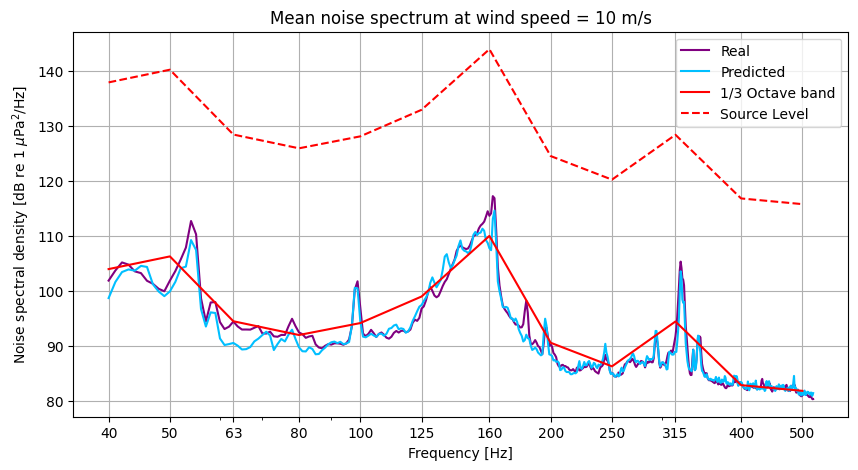

In [98]:
f,SPL,f_,SL_=compute_spectra_and_plot(wspeed,spec_type)#0 for real spectra

In [99]:
#add some values to f_ ([1500, 2000, 2500]) and SL_ ([235, 235, 235])
#f_ = np.append(f_, [1500, 2000, 2500, 10000])
#SL_ = np.append(SL_, [115,115,115,115])

# 4. Load seabed geoacoustic properties

p wave celerity ($c_p$), density and attenuation are chosen based on the sellected seabed type (bottom type), from *Hamilton et al., 1980* (https://doi.org/10.1121/1.385100)

| Bottom type | $c_p$ (m/s) | Density (kg/m³) | Attenuation (dB/λ$_s$) |
|-------------|---------------|----------------|---------------------|
| Clay        | 1500          | 1.5            | 1                   |
| Silt        | 1575          | 1.7            | 1.5                 |
| Sand        | 1650          | 1.9            | 2.5                 |
| Gravel      | 1800          | 2.0            | 1.5                 |
| Moraine     | 1950          | 2.1            | 1                   |
| Chalk       | 2400          | 2.2            | 0.5                 |
| Limestone   | 3000          | 2.4            | 0.2                 |
| Basalt      | 5250          | 2.7            | 0.2                 |

In [100]:
sediment_selector(sediment_type)

Selected sediment: Basalt
Bottom celerity: 5250.0 m/s
Bottom density: 2700.0 kg/m³
Bottom attenuation: 0.2 dB/λₛ


# 5. Load *EMODnet* Bathymetry

Bathymetry from the sellected source to receiver area is downloaded using ERDDAP server, from *EMODnet* (https://ieeexplore.ieee.org/document/8867250). Two plots are displayed and stored, first with 0.3 degrees margins, and second with 0.1 degrees.

Bathymetry dataset url: https://erddap.emodnet.eu/erddap/griddap/dtm_2020_v2_e0bf_e7e4_5b8f.csv?elevation[(27.779999999999998):1:(28.387287)][(-16.774221):1:(-16.099999999999998)]
Bathymetry downloaded from Emodnet. Grid shape:  (584, 653)


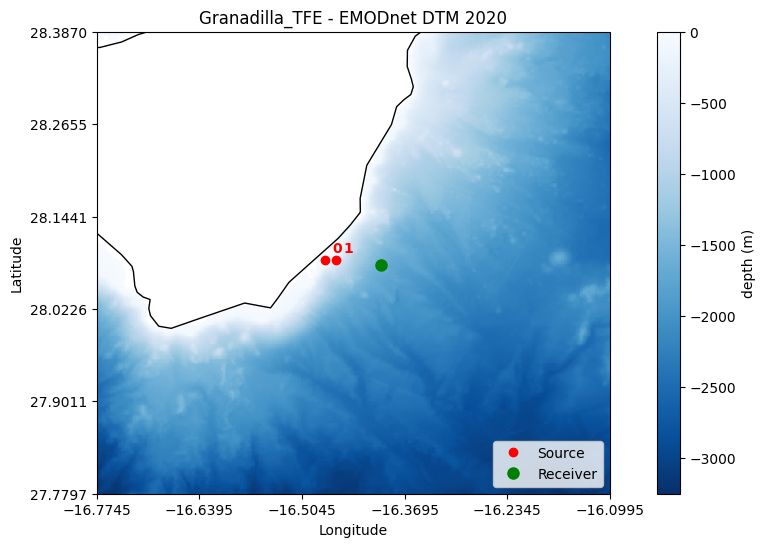

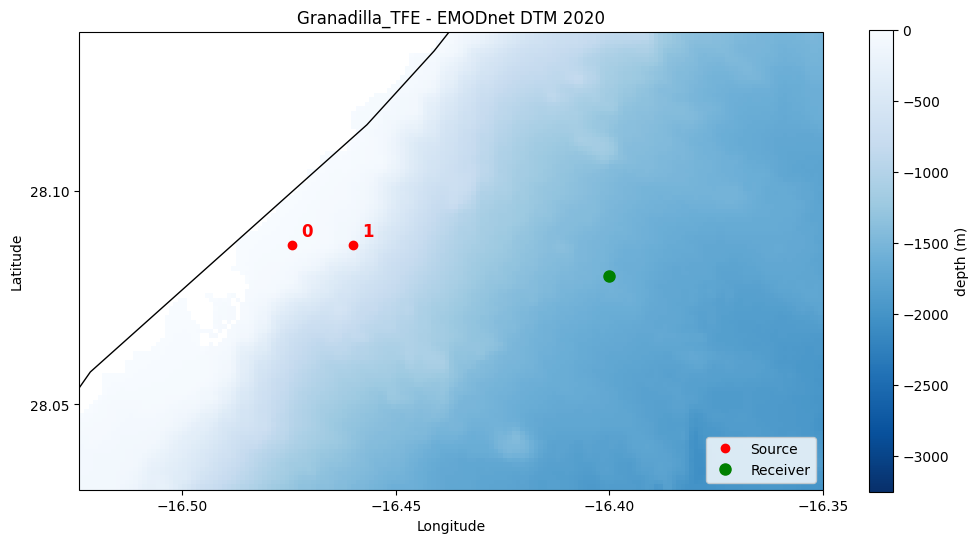

In [101]:
lon,lat,elev=Emodnet_bathy(Src_lon_all,Src_lat_all,Rec_lon,Rec_lat)
plot_bathymetry()
plot_bathymetry_zoom()


# 6. Load temperature and salinity

Temperature and salinity are downloaded using *Copernicus Marine Toolbox API* (https://help.marine.copernicus.eu/en/articles/8283072-copernicus-marine-toolbox-api-subset) and stored in `PWT_outputs/<section_name>`.
In this case we use *Copernicus Marine, Global Ocean Physics Reanalysis* (https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_PHY_001_030).

In [102]:
temp_sal_data(Src_lon_all,Src_lat_all,Rec_lon,Rec_lat,date_ssp)

INFO - 2026-11-20T14:30:01Z - Selected dataset version: "202311"
INFO - 2026-11-20T14:30:01Z - Selected dataset part: "default"
INFO - 2026-11-20T14:30:04Z - Starting download. Please wait...


  0%|          | 0/50 [00:00<?, ?it/s]

INFO - 2026-11-20T14:30:26Z - Successfully downloaded to /Users/ionurtiaga/Documents/PUREWIND/PureWindTool 2/PWT_outputs/Granadilla_TFE/tempsal.nc


# 7. Run *RAM/Bellhop* propagation model

Publicly (http://oalib.hlsresearch.com/AcousticsToolbox/) available RAM (if f<1kHz) or Bellhop (if f>1kHz)  model is run.

If a section with the same name has **already been processed**, the propagation model will be **skipped**.  

<span style="color:red">**IMPORTANT:**</span> If you make any modifications to that section, either **change the section name** or **delete the corresponding folder** in `PWT_outputs/<section_name>`.



In [103]:
Propagation_model()

🆕 SPLrec.npz not found. Running propagation model automatically.

Frequency:  40  Hz
___________
Source: 0
Data from (COPERNICUS):  2019-09-16 00:00:00
Max range = 7339.433475807676  m
Max Emodnet Depth = -1567.0  m
PyRAM proc time: 0.72 seconds

Source: 1
Data from (COPERNICUS):  2019-09-16 00:00:00
Max range = 5952.184570375958  m
Max Emodnet Depth = -1567.0  m
PyRAM proc time: 0.59 seconds


Frequency:  50  Hz
___________
Source: 0
PyRAM proc time: 0.69 seconds

Source: 1
PyRAM proc time: 0.57 seconds


Frequency:  63  Hz
___________
Source: 0
PyRAM proc time: 0.67 seconds

Source: 1
PyRAM proc time: 0.55 seconds


Frequency:  80  Hz
___________
Source: 0
PyRAM proc time: 0.65 seconds

Source: 1
PyRAM proc time: 0.53 seconds


Frequency:  100  Hz
___________
Source: 0
PyRAM proc time: 0.64 seconds

Source: 1
PyRAM proc time: 0.52 seconds


Frequency:  125  Hz
___________
Source: 0
PyRAM proc time: 0.63 seconds

Source: 1
PyRAM proc time: 0.52 seconds


Frequency:  160  Hz
__________

# 8. Plot desired figures

## Sound speed profiles
Plots the deepest sound speed profile in the specified source to receiver section

In [104]:
create_ssp_widget()

## SPL section at specified section for a given frequency
Plots the SPL section from the specified source to the receiver, at specified frequency. 

<span style="color:red">**Note:**</span>  Processing time increases significantlly with section range, depth or resolution!

In [105]:
plot_SPL_section()

Button(button_style='info', description='Plot section', style=ButtonStyle())

Output()

## Cumlative SPL spectrum at receiver location
Plots SPL cumulative (all sources) spectrum, across depth at the receiver location (color indicates the SPL).

In [106]:
plot_SPL_rec_all_depth()

Button(button_style='info', description='Plot SPL at rec', style=ButtonStyle())

Output()

## Cumulative SPL spectrum at receiver location, at specified depth
Plots SPL cumulative (from all sources) spectrum at receiver location, at specified depth. Máximum SPL depth is set by default.

In [107]:
plot_SPL_rec()

z_SPL shape: (1592,), SPL_rec shape: (12, 1592)


## Cumulative vs single source SPL (at specified depth)

Plot **every source** SPL againts cumulative SPL spectrum, at specified depth. Máximum SPL depth is set by default.

In [108]:
plot_SPL_rec_all_sources()

Plot the **specified source** SPL against the cumulative SPL spectrum, at specified depth. Máximum SPL depth is set by default.

In [109]:
plot_SPL_rec_ii()

## Plot weighted SPL against Audiograms
Plot weighted SPL spectra for each hearing group  against each group audiogram (*Southall et al., 2019*; https://doi.org/10.1578/AM.45.2.2019.125), at specified depth. Máximum SPL depth is set by default.

| Marine mammal hearing group       | ID  | Genera (or species) included |
|----------------------------------|-----|-----------------------------|
| Low-frequency cetaceans           | LF  | Balaenidae (Balaena, Eubalaena spp.); Balaenopteridae (Balaenoptera physalus, B. musculus, B. acutorostrata, B. bonaerensis, B. borealis, B. edeni, B. omurai; Megaptera novaeangliae); Neobalaenidae (Caperea); Eschrichtiidae (Eschrichtius) |
| High-frequency cetaceans          | HF  | Physeteridae (Physeter); Ziphiidae (Berardius spp., Hyperoodon spp., Indopacetus, Mesoplodon spp., Tasmacetus, Ziphius); Delphinidae (OrcinusDelphinus, Feresa, Globicephala spp., Grampus, Lagenodelphis, Lagenorhynchus acutus, L. albirostris, L. obliquidens, L. obscurus, Lissodelphis spp., Orcaella spp., Peponocephala, Pseudorca, Sotalia spp., Sousa spp., Stenella spp., Steno, Tursiops spp); Montodontidae (Delphinapterus, Monodon); Plantanistidae (Plantanista) |
| Very high-frequency cetaceans     | VHF | Delphinidae (Cephalorhynchus spp.; Lagenorhynchus cruciger, L. australis); Phocoenidae (Neophocaena spp., Phocoena spp., Phocoenoides); Iniidae (Inia); Kogiidae (Kogia); Lipotidae (Lipotidae); Pontoporiidae (Pontoporia) |
| Sirenians                         | SI  | Trichechidae (Trichechus spp.); Dugongidae (Dugong) |
| Phocid carnivores in water        | PCW | Phocidae (Cystophora, Erignathus, Halichoerus, Histriophoca, Hydrurga, Leptonychotes, Lobodon, Mirounga spp., Monachus, Neomonachus, Ommatophoca, Pagophilus, Phoca spp., Pusa spp.) |
| Other marine carnivores in water  | OCW | Odobenidae (Odobenus); Otariidae (Arctocephalus californicus, Callorhinus, Eumetopias, Neophoca, Otaria, Phocarctos, Zalophus spp.); Ursidae (Ursus maritimus); Mustelidae (Enhydra, Lontra felina) |


In [110]:
plot_Audiogram()

When a weighted SPL (continuous line) from a specific auditory group exceeds the corresponding group audiogram (dashed line), it means this auditory group is threatened.